In [340]:
# Explained:
# what is derivative, gradient
# what is backpropagation and how we can use it to calculate gradients
# what is tanh (squashing function - used for activation function)

In [319]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [320]:
def f(x):
    return 3 * x ** 2 - 4 * x + 5

In [321]:
f(3.0)

20.0

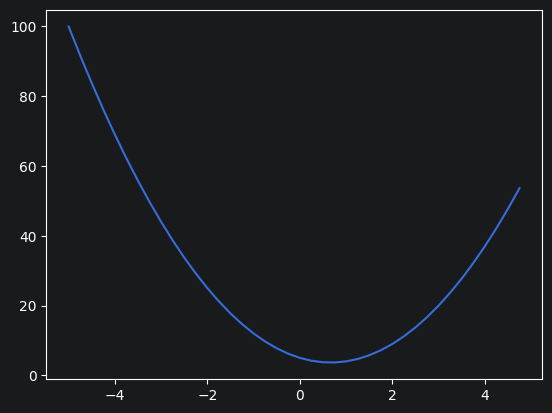

In [322]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [323]:
# derivative represent the rate of changing at a certain point
# basically what will happen if we slightly increase x:
# if it goes up = big derivative
# if it goes down = negative derivative
h = 0.000001
x = 2 / 3  # try changing this number to see how derivative changes depending on where are you on the graph
(f(x + h) - f(x)) / h

2.999378523327323e-06

In [324]:
# another example with other function
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [325]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a * b + c
a += h
d2 = a * b + c

print('d1', d1)  # 4.0
print('d2', d2)  # 3.999
print('slope', (d2 - d1) / h)  # -3.0 (expected as increasing a = decreases the result)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [326]:
# Here we setup simple class that we will use to draw graph of the expression
# (a*b+c)*f

class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        out = Value((self.data + other.data), (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value((self.data + other.data), (self, other), '*')
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), 'tanh')
        return out


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b;
e.label = 'e'
d = e + c;
d.label = 'd'
f = Value(-2.0, label='f')
L = d * f;
L.label = 'L'
L

Value(data=7.0, grad=0.0)

In [327]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


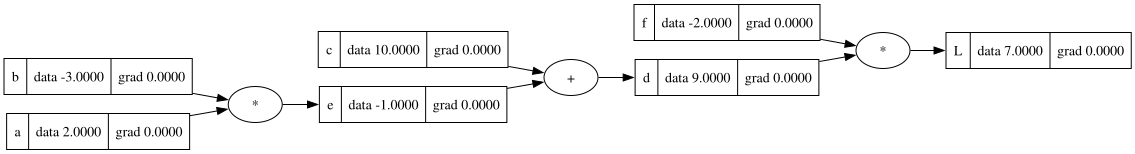

In [328]:
draw_dot(L)

In [329]:
L.grad = 1  # the derivative of L relative to L is 1

h = 0.00000001

f.grad = (((f.data + h) * d.data) - (f.data * d.data)) / h
d.grad = ((f.data * (d.data + h)) - (f.data * d.data)) / h

# now we go backwards through the graph

# c = d + ...
# the derivative of c with respect to d is 1 (because '+')
# so the gradient just passes through unchanged

c.grad = 1 * d.grad
e.grad = 1 * d.grad

# b = a * e
# the derivative of b with respect to e is a (2)
#
# so the derivative of L with respect to e is:
#
# derivative of L with respect to b
# *
# derivative of b with respect to e
#
# e.grad = b.grad * a.data
#
# More generally:
# current.grad = next.grad * derivative of next with respect to current


# now we do the same thing for a and b
#
# e = a * b
#
# derivative of e with respect to a is b
# derivative of e with respect to b is a
#
# so we multiply each local derivative by e.grad

a.grad = b.data * e.grad
b.grad = a.data * e.grad

In [330]:
# ok now we should be able to increase L
# by increasing all leaf nodes in the direction of their gradient
print(f"L before: {L.data}")

a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f

print(f"L after: {L.data}")


L before: 7.0
L after: 7.090000000341206


In [331]:
def check_grad():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b;
    e.label = 'e'
    d = e + c;
    d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f;
    L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    e = a * b;
    e.label = 'e'
    d = e + c;
    d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f;
    L.label = 'L'
    L2 = L.data

    print((L2 - L1) / h)


check_grad()

0.9999999999994458


In [332]:
# Now neurons in NNs are modeled mathematically:

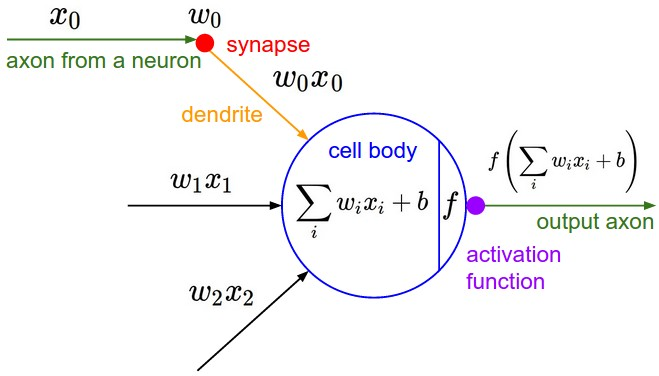

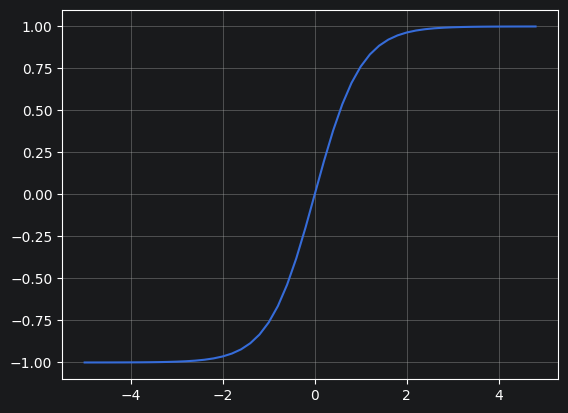

In [333]:
# The activation function is usually some kind of squashing function - like tanh
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)));
plt.grid();

In [334]:
# Here I will redefine the value class ( including tanh function and _backward function )
# The goal of the backward function is to have a function to call on each Value object
# that will set the gradient of it's children

In [335]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad

        out._backward = _backward

        return out

        # so we don't have to manually call node._backward() on every non leaf node
        # we build a function that creates topological sort of the nodes and then call on each node ._backward()
        # starting from the root

    def backward(self):
        topo=[]
        visited=set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad=1.0

        for node in reversed(topo):
            node._backward()



In [336]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1;
x1w1.label = 'x1*w1'
x2w2 = x2 * w2;
x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2;
x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b;
n.label = 'n'
o = n.tanh();
o.label = 'o'
o.grad = 1

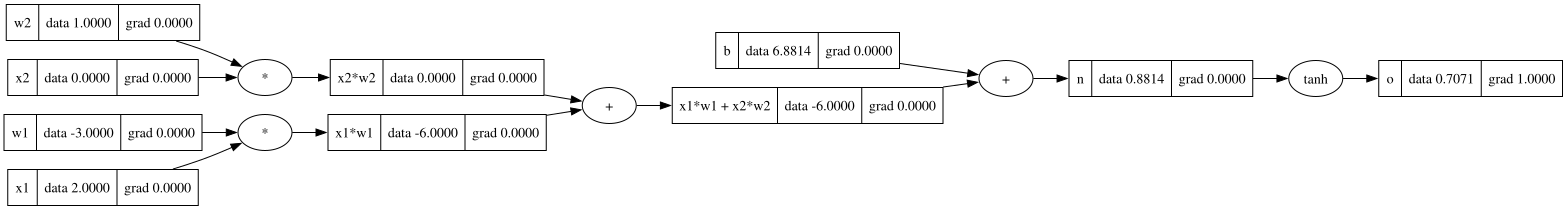

In [337]:
draw_dot(o)

In [338]:
# o._backward()
# n._backward()
# x1w1x2w2._backward()
# x1w1._backward()
# x2w2._backward() same as
o.backward()

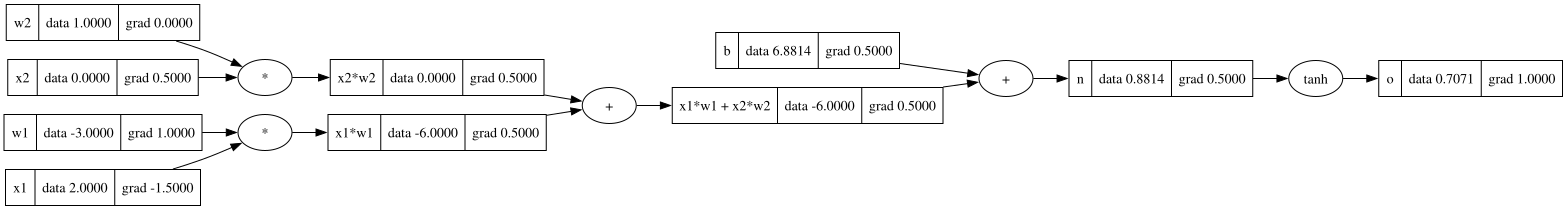

In [339]:
draw_dot(o) # 1:22 of the video